# A0: station-level observation-driven correction of MEPS wind (small experiment)

Track A, following Peduto et al. 2026 (ORCA, doi:10.1029/2025JH001174), with Gaussian processes instead
of a transformer. This is the first small experiment, on the data already downloaded. It
uses no gridded operator yet.

**Question.** How much does the latest station obs-forecast (observation minus MEPS)
reduce MEPS 10 m wind error, and up to which lead? Every correction is a weighted
combination of station obs-forecast values, evaluated in two settings:

* **weighted stations including target**: the target station reports at init time, so its
  own obs-forecast is one of the weighted inputs. Its training-period data are also used
  in training.
* **weighted stations excluding target**: the target station is held out completely. Its
  obs-forecast is not an input, and its data are not used in training: the stations are
  split into 5 spatially blocked groups, and each group is predicted by a model trained on
  the other 4. This is the setting for locations without a station, i.e. most of the 1 km
  grid.

**Setup**

* Data: MEPS 2.5 km deterministic runs 2018-01-01 – 2018-07-15 (00 / 12 UTC). Frost
  stations in Nordland / Troms / Finnmark inside the MEPS window with > 50 % hourly wind,
  87 in all. Obs are hourly 10 m wind, quality ≤ 2. MEPS is bilinear at the station.
* Target: residual y = o(t + τ) − MEPS_t(τ) in (u, v), τ = 0–12 h hourly and 18–66 h
  6-hourly.
* Information at issue time: the obs-forecast d(t) = o(t) − MEPS_{t−12}(12), i.e. the
  previous run, since run t is not out yet. Observations at valid times are never inputs.
* Split by init: train 2018-01-01 – 04-30, test 2018-06-01 – 07-15 (May is left as a
  gap). Train is winter / spring and test is summer, so there is a seasonal shift.
* Metric: vector RMSE of (u, v) in m/s, per lead. Mean vector error (the metric of
  Peduto et al.) is shown once for reference.

**Models.** All predict y, per lead.

| method | description | stations used |
|---|---|---|
| `MEPS uncorrected` | no correction (y = 0) | — |
| `Target-station persistence` | β_τ · d_s(t): the target station's obs-forecast, scaled per lead | target only |
| `Ridge regression, weighted stations including target` | ridge regression on MEPS u, v at the target, inverse-distance-weighted mean of the other stations' d(t), the target's d_s(t), hour / day-of-year (sin, cos), altitude, MEPS orography − altitude | target + other stations |
| `Ridge regression, weighted stations excluding target` | the same without the target's d_s(t) | other stations |
| `Gaussian process with elevation, weighted stations including target` | spatial Gaussian process of d(t) (Matérn 5/2 in distance × Gaussian in elevation difference); posterior mean at the target, scaled by ρ_τ | target + other stations |
| `Gaussian process with elevation, weighted stations excluding target` | the same, conditioned without the target station; kernel and ρ_τ refitted for each held-out group | other stations |
| `Gaussian process distance only, weighted stations excluding target` | the same with a distance-only kernel (terrain vs distance, RQ2) | other stations |


## Summary of results

Test set: summer 2018, 87 stations, about 7 300 samples per lead. The table gives vector
RMSE in m/s, with the change vs MEPS in brackets.

| method | +3 h | +6 h | +12 h | +24 h | +48 h | +66 h |
|---|---|---|---|---|---|---|
| MEPS uncorrected | 3.65 | 3.61 | 3.69 | 3.77 | 3.88 | 4.10 |
| Target-station persistence | 2.81 (−22.9 %) | 3.09 (−14.5 %) | 3.42 (−7.3 %) | 3.57 (−5.2 %) | 3.82 (−1.7 %) | 4.07 (−0.8 %) |
| Ridge regression, weighted stations including target | **2.77 (−24.1 %)** | **2.97 (−17.7 %)** | **3.28 (−11.2 %)** | **3.40 (−9.7 %)** | **3.61 (−7.0 %)** | **3.89 (−5.1 %)** |
| Gaussian process with elevation, weighted stations including target | 2.99 (−18.1 %) | 3.16 (−12.5 %) | 3.46 (−6.3 %) | 3.61 (−4.3 %) | 3.84 (−1.2 %) | 4.08 (−0.6 %) |
| Ridge regression, weighted stations excluding target | 3.48 (−4.5 %) | 3.42 (−5.2 %) | 3.53 (−4.3 %) | 3.60 (−4.5 %) | 3.71 (−4.6 %) | 3.98 (−3.0 %) |
| Gaussian process with elevation, weighted stations excluding target | 3.51 (−3.8 %) | 3.50 (−3.1 %) | 3.63 (−1.5 %) | 3.73 (−0.9 %) | 3.88 (−0.2 %) | 4.10 (0.0 %) |
| Gaussian process distance only, weighted stations excluding target | 3.50 (−4.1 %) | 3.49 (−3.3 %) | 3.62 (−1.9 %) | 3.73 (−1.0 %) | 3.88 (−0.1 %) | 4.10 (−0.1 %) |

* **Including the target station:** its own obs-forecast gives −15 to −24 % at +3–6 h,
  falling to a few % by +24–48 h. Ridge regression, weighted stations including target, is
  best at every lead from +3 h.
* **Excluding the target station** (no input from it and no use of its data in training):
  the other stations' obs-forecast gives only −3 to −5 % up to +6 h. The ridge regression's
  gain at long leads (−3 to −5 % up to +66 h) is mostly a static bias correction, not
  information from the other stations.
* **High winds (≥ 10 m/s):** the ridge regressions become worse than MEPS at long leads,
  up to +10 % / +11 % RMSE at +66 h. The Gaussian processes stay within ±0.3 % of MEPS
  or better.
* **Elevation kernel vs distance-only kernel:** no difference in overall RMSE. At high
  winds the distance-only kernel is slightly worse than MEPS (+0.4 to +1.3 %) while the
  elevation kernel is not.

The details are in sections 1–7, each followed by its result. The interpretation and next
steps are in section 8. All tables are also saved under
`/cluster/work/projects/nn8106k/siyan/windcast/results/a0/`.


In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, '..')
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from windcast.station_correction import load, SpatialGP, idw, vec_rmse, crps_gauss
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

d = load('/cluster/work/projects/nn8106k/siyan/windcast/cache/stations_meps_2018-01-01_2018-07-15.npz')
inits, leads = pd.DatetimeIndex(d['inits']), d['leads']
N, L, S = len(inits), len(leads), len(d['station'])
tr = (inits >= '2018-01-01') & (inits < '2018-05-01')
te = (inits >= '2018-06-01') & (inits <= '2018-07-15')
y, fc, omf = d['y'].astype(float), d['fc'].astype(float), d['omf'].astype(float)
d0 = omf[:, 0]                                    # obs-forecast at init time
xy, z = d['xy'].astype(float), d['masl'].astype(float)
print(f'{N} runs ({tr.sum()} train, {te.sum()} test), {L} leads, {S} stations')
print('stations with obs-forecast at init time, mean per run:', np.isfinite(d0[..., 0]).sum(1).mean().round(1))

390 runs (238 train, 89 test), 22 leads, 87 stations
stations with obs-forecast at init time, mean per run: 81.3


## 1. Does the obs-forecast persist? Correlation with the future residual vs lead and distance

corr(d_s'(t), y_s(t + τ)), with u and v pooled, on train, binned by station distance.

dist,same station,1-25 km,25-50 km,50-100 km,100-200 km,200-400 km
lead,,,,,,
0,0.92,0.10,0.13,0.06,0.05,0.05
3,0.65,0.07,0.12,0.07,0.06,0.05
6,0.55,0.05,0.10,0.06,0.05,0.05
12,0.43,0.03,0.09,0.05,0.04,0.04
30,0.29,0.02,0.06,0.03,0.03,0.03
42,0.25,0.02,0.06,0.03,0.02,0.02
66,0.18,-0.00,0.03,0.01,0.01,0.01


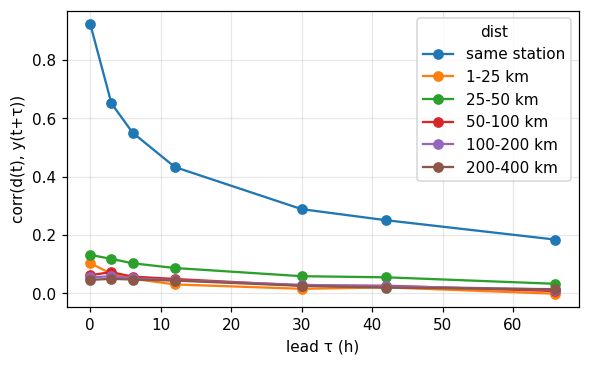

In [2]:
r = np.linalg.norm(xy[:, None] - xy[None], axis=-1)
bins = [0, 1, 25, 50, 100, 200, 400]
show = [0, 3, 6, 12, 15, 17, 21]   # lead indices
rows = []
for j in show:
    for b0, b1 in zip(bins[:-1], bins[1:]):
        pr = np.argwhere((r >= b0) & (r < b1))
        a = d0[tr][:, pr[:, 1]]; b = y[tr, j][:, pr[:, 0]]
        a, b = a.reshape(-1), b.reshape(-1); m = np.isfinite(a) & np.isfinite(b)
        rows.append(dict(lead=int(leads[j]), dist=f'{b0}-{b1} km' if b1 > 1 else 'same station', r=np.corrcoef(a[m], b[m])[0, 1]))
corr = pd.DataFrame(rows).pivot(index='lead', columns='dist', values='r')
corr = corr[['same station'] + [f'{b0}-{b1} km' for b0, b1 in zip(bins[1:-1], bins[2:])]]
display(corr.round(2))
ax = corr.plot(marker='o', figsize=(6, 3.5)); ax.set_ylabel('corr(d(t), y(t+τ))'); ax.set_xlabel('lead τ (h)'); plt.show()

**Result 1.** Correlation between d(t) and the residual at t + τ, on train:

| lead | same station | 1–25 km | 25–50 km | 50–100 km | 100–200 km | 200–400 km |
|---|---|---|---|---|---|---|
| +0 h | 0.92 | 0.10 | 0.13 | 0.06 | 0.05 | 0.05 |
| +3 h | 0.65 | 0.07 | 0.12 | 0.07 | 0.06 | 0.05 |
| +6 h | 0.55 | 0.05 | 0.10 | 0.06 | 0.05 | 0.05 |
| +12 h | 0.43 | 0.03 | 0.09 | 0.05 | 0.04 | 0.04 |
| +30 h | 0.29 | 0.02 | 0.06 | 0.03 | 0.03 | 0.03 |
| +66 h | 0.18 | 0.00 | 0.03 | 0.01 | 0.01 | 0.01 |

The station's own obs-forecast stays informative for a long time: correlation 0.55 at
+6 h and still 0.18 at +66 h. Other stations' differences are almost uncorrelated
(≤ 0.13), already within 25 km. MEPS wind errors at these stations are mainly local.


## 2. Spatial Gaussian process of the init-time obs-forecast

Hyperparameters are fitted by marginal likelihood on train. Each time and component is an independent draw, and u and v share the kernel.

In [3]:
gp = SpatialGP(xy, z, use_z=True);  hp, nll = gp.fit(d0[tr])
gpd = SpatialGP(xy, z, use_z=False); hpd, nlld = gpd.fit(d0[tr])
print('distance x elevation:', {k: round(float(v), 2) for k, v in hp.items()}, 'nll/obs', round(nll, 4))
print('distance only       :', {k: round(float(v), 2) for k, v in hpd.items()}, 'nll/obs', round(nlld, 4))
post = gp.posterior(d0); postd = gpd.posterior(d0)

# strict hold-out: for "excluding target", kernel parameters are refitted 5 times, each time
# without one spatially blocked group of stations (the same groups as the ridge regression)
folds = KMeans(5, n_init=10, random_state=0).fit_predict(xy)
def fold_posteriors(use_z):
    out = []
    for k in range(5):
        g = SpatialGP(xy, z, use_z=use_z)
        dk = d0[tr].copy(); dk[:, folds == k] = np.nan
        h, _ = g.fit(dk)
        print(f'  group {k} ({(folds == k).sum()} stations held out):', {kk: round(float(v), 2) for kk, v in h.items()})
        out.append(g.posterior(d0)['excluding_target'])
    return out
print('distance x elevation, per held-out group'); fold_post = fold_posteriors(True)
print('distance only, per held-out group'); fold_postd = fold_posteriors(False)

distance x elevation: {'sf2': 3.26, 'ell_km': 70.02, 'sn2': 5.6, 'ell_z_m': 296.83} nll/obs 1.543
distance only       : {'sf2': 1.41, 'ell_km': 140.39, 'sn2': 7.36} nll/obs 1.5521


distance x elevation, per held-out group


  group 0 (19 stations held out): {'sf2': 2.41, 'ell_km': 76.95, 'sn2': 5.93, 'ell_z_m': 345.54}


  group 1 (11 stations held out): {'sf2': 3.9, 'ell_km': 54.41, 'sn2': 5.03, 'ell_z_m': 291.86}


  group 2 (26 stations held out): {'sf2': 5.1, 'ell_km': 49.94, 'sn2': 4.53, 'ell_z_m': 162.01}


  group 3 (18 stations held out): {'sf2': 2.95, 'ell_km': 95.46, 'sn2': 5.59, 'ell_z_m': 375.2}


... (3 outputs left out)

  group 1 (11 stations held out): {'sf2': 1.3, 'ell_km': 129.73, 'sn2': 7.49}


  group 2 (26 stations held out): {'sf2': 1.46, 'ell_km': 142.97, 'sn2': 8.11}


  group 3 (18 stations held out): {'sf2': 1.56, 'ell_km': 148.69, 'sn2': 6.83}


  group 4 (13 stations held out): {'sf2': 1.56, 'ell_km': 127.18, 'sn2': 7.37}


**Result 2.** Fitted kernels on all stations, per obs component:

| kernel | spatial variance (m²/s²) | length scale | elevation scale | nugget (m²/s²) | NLL / obs |
|---|---|---|---|---|---|
| distance × elevation | 3.26 | 70 km | 297 m | 5.60 | 1.543 |
| distance only | 1.41 | 140 km | — | 7.36 | 1.552 |

Refitted with one group of stations held out each time (the 5 groups used for "excluding
target"):

* distance × elevation: spatial variance 2.4–5.1, length scale 50–95 km, elevation scale
  160–375 m, nugget 4.5–5.9;
* distance only: spatial variance 1.3–1.6, length scale 116–149 km, nugget 6.8–8.1.

The station-local part (the nugget) is larger than the spatially coherent part. The
elevation kernel's parameters vary much more between groups, so they depend on which
stations are in training.


## 3. Per-lead models

All models are scored on the same samples: valid target, own obs-forecast available at init time, and at least 3 other stations reporting.

In [4]:
T_ = np.arange(N)
hour = np.array([(inits + pd.Timedelta(hours=int(l))).hour for l in leads]).T      # (N, L)
doy = np.array([(inits + pd.Timedelta(hours=int(l))).dayofyear for l in leads]).T
I = idw(xy, d0)                                                                    # (N, S, 2)
own = d0
nother = np.isfinite(d0[..., 0]).sum(1)[:, None] - 1
base = np.isfinite(own[..., 0]) & np.isfinite(I[..., 0]) & (nother >= 3)          # (N, S)

def ridge_X(j, own_in):
    f = fc[:, j]
    cols = [f[..., 0], f[..., 1], I[..., 0], I[..., 1],
            np.repeat(np.sin(2*np.pi*hour[:, j]/24)[:, None], S, 1), np.repeat(np.cos(2*np.pi*hour[:, j]/24)[:, None], S, 1),
            np.repeat(np.sin(2*np.pi*doy[:, j]/366)[:, None], S, 1), np.repeat(np.cos(2*np.pi*doy[:, j]/366)[:, None], S, 1),
            np.broadcast_to(z, (N, S)), np.broadcast_to(d['oro'] - z, (N, S))]
    if own_in:
        cols += [own[..., 0], own[..., 1]]
    return np.stack(cols, -1)                                                       # (N, S, F)

P = {k: np.full((N, L, S, 2), np.nan) for k in ['MEPS uncorrected', 'Target-station persistence', 'Ridge regression, weighted stations including target', 'Ridge regression, weighted stations excluding target', 'Gaussian process with elevation, weighted stations including target', 'Gaussian process with elevation, weighted stations excluding target', 'Gaussian process distance only, weighted stations excluding target']}
GP_ELEV_IN, GP_ELEV_EX, GP_DIST_EX = ('Gaussian process with elevation, weighted stations including target',
    'Gaussian process with elevation, weighted stations excluding target', 'Gaussian process distance only, weighted stations excluding target')
V = {k: np.full((N, L, S), np.nan) for k in ['Gaussian process with elevation, weighted stations including target', 'Gaussian process with elevation, weighted stations excluding target', 'Gaussian process distance only, weighted stations excluding target']}
for j in range(L):
    yj = y[:, j]
    m_tr = base & np.isfinite(yj[..., 0]) & tr[:, None]
    m_te = base & np.isfinite(yj[..., 0]) & te[:, None]
    P['MEPS uncorrected'][:, j][m_te] = 0.0
    # persistence of the target station's obs-forecast, beta fitted on train
    b = np.nansum(own[m_tr] * yj[m_tr]) / np.nansum(own[m_tr] ** 2)
    P['Target-station persistence'][:, j][m_te] = b * own[m_te]
    # ridge regression, u and v separately
    for name, own_in in [('Ridge regression, weighted stations including target', True), ('Ridge regression, weighted stations excluding target', False)]:
        X = ridge_X(j, own_in)
        if own_in:
            groups = [(np.ones(S, bool), np.ones(S, bool))]
        else:
            groups = [(folds != k, folds == k) for k in range(5)]
        for s_tr, s_te in groups:
            mt, me = m_tr & s_tr[None], m_te & s_te[None]
            sc = StandardScaler().fit(X[mt])
            for c in range(2):
                reg = Ridge(alpha=1.0).fit(sc.transform(X[mt]), yj[mt][:, c])
                out = P[name][:, j, :, c]; out[me] = reg.predict(sc.transform(X[me]))
    # Gaussian process: y ~ rho * m, Var = rho^2 v + e, rho and e fitted per lead on train
    def gp_fit_predict(name, pm, pv, s_tr, s_te):
        mt = m_tr & s_tr[None] & np.isfinite(pm[..., 0])
        rj = np.sum(pm[mt] * yj[mt]) / np.sum(pm[mt] ** 2)
        e = np.mean((yj[mt] - rj * pm[mt]) ** 2) - rj ** 2 * np.mean(pv[mt])
        me = m_te & s_te[None] & np.isfinite(pm[..., 0])
        P[name][:, j][me] = rj * pm[me]
        V[name][:, j][me] = rj ** 2 * pv[me] + max(e, 1e-3)
    allst = np.ones(S, bool)
    gp_fit_predict(GP_ELEV_IN, *post['including_target'], allst, allst)
    for k in range(5):
        gp_fit_predict(GP_ELEV_EX, *fold_post[k], folds != k, folds == k)
        gp_fit_predict(GP_DIST_EX, *fold_postd[k], folds != k, folds == k)

TEST = base[:, None, :] & np.isfinite(y[..., 0]) & te[:, None, None]
for k in P:
    assert np.isfinite(P[k][TEST][:, 0]).all(), k
print('test samples per lead:', TEST.sum((0, 2))[[0, 6, 12, 21]])

test samples per lead: [7333 7297 7295 7231]


## 4. Results: vector RMSE per lead (test, summer 2018)

In [5]:
def table(mask, metric='rmse'):
    out = {}
    for k, p in P.items():
        row = []
        for j in range(L):
            m = mask[:, j]
            err = (y[:, j][m] - p[:, j][m])
            row.append(np.sqrt((err**2).sum(-1).mean()) if metric == 'rmse' else np.linalg.norm(err, axis=-1).mean())
        out[k] = row
    return pd.DataFrame(out, index=pd.Index(leads, name='lead (h)'))

R = table(TEST)
imp = (1 - R.div(R['MEPS uncorrected'], axis=0)) * 100
print('vector RMSE (m/s)')
display(R.round(2))
print('improvement over MEPS (%)')
display(imp.drop(columns='MEPS uncorrected').round(1))

vector RMSE (m/s)


,MEPS uncorrected,Target-station persistence,"Ridge regression, weighted stations including target","Ridge regression, weighted stations excluding target","Gaussian process with elevation, weighted stations including target","Gaussian process with elevation, weighted stations excluding target","Gaussian process distance only, weighted stations excluding target"
lead (h),,,,,,,
0,3.60,1.35,1.38,3.44,2.39,3.45,3.46
1,3.60,2.35,2.35,3.47,2.74,3.45,3.46
2,3.60,2.61,2.61,3.47,2.86,3.46,3.46
3,3.65,2.81,2.77,3.48,2.99,3.51,3.50
4,3.65,2.91,2.88,3.51,3.04,3.51,3.50
5,3.61,2.97,2.92,3.46,3.08,3.49,3.48
6,3.61,3.09,2.97,3.42,3.16,3.50,3.49
7,3.62,3.17,3.05,3.44,3.23,3.53,3.51
8,3.63,3.23,3.10,3.45,3.28,3.54,3.53


improvement over MEPS (%)


,Target-station persistence,"Ridge regression, weighted stations including target","Ridge regression, weighted stations excluding target","Gaussian process with elevation, weighted stations including target","Gaussian process with elevation, weighted stations excluding target","Gaussian process distance only, weighted stations excluding target"
lead (h),,,,,,
0,62.5,61.7,4.3,33.4,4.0,3.9
1,34.8,34.8,3.7,24.0,4.1,3.9
2,27.6,27.7,3.7,20.6,4.0,4.1
3,22.9,24.1,4.5,18.1,3.8,4.1
4,20.1,21.1,3.8,16.6,3.8,4.0
5,17.7,19.0,4.1,14.8,3.4,3.7
6,14.5,17.7,5.2,12.5,3.1,3.3
7,12.4,15.9,5.2,10.8,2.7,3.1
8,11.1,14.6,4.9,9.6,2.4,2.7


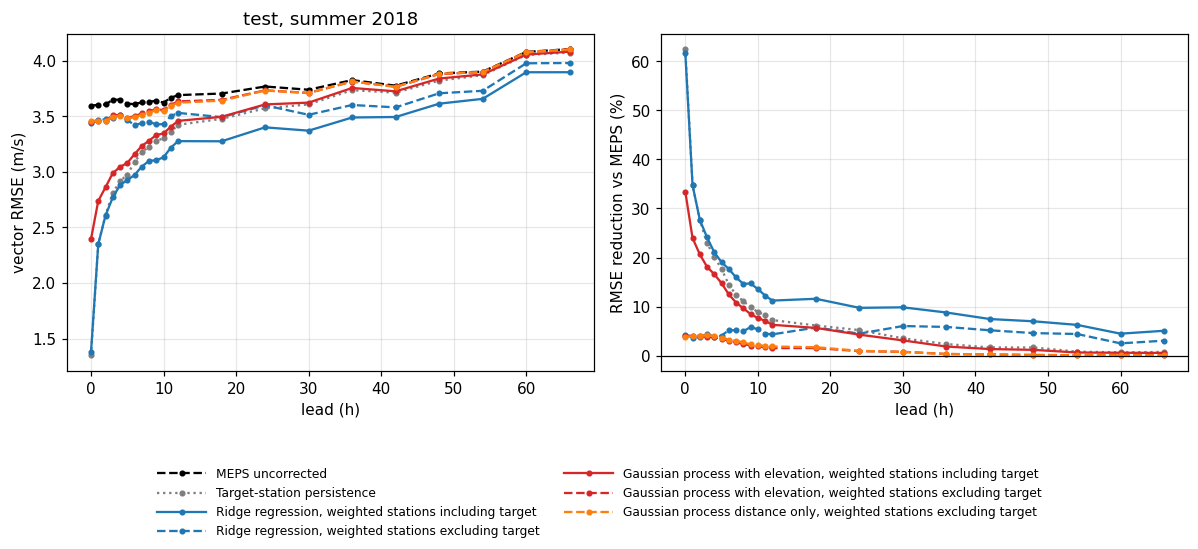

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
sty = {'MEPS uncorrected': 'k--', 'Target-station persistence': 'C7:', 'Ridge regression, weighted stations including target': 'C0-', 'Ridge regression, weighted stations excluding target': 'C0--', 'Gaussian process with elevation, weighted stations including target': 'C3-', 'Gaussian process with elevation, weighted stations excluding target': 'C3--', 'Gaussian process distance only, weighted stations excluding target': 'C1--'}
for k in R:
    ax[0].plot(leads, R[k], sty[k], marker='.', label=k)
    if k != 'MEPS uncorrected': ax[1].plot(leads, imp[k], sty[k], marker='.', label=k)
ax[0].set(xlabel='lead (h)', ylabel='vector RMSE (m/s)', title='test, summer 2018'); 
ax[1].set(xlabel='lead (h)', ylabel='RMSE reduction vs MEPS (%)'); ax[1].axhline(0, c='k', lw=.8)
fig.legend(*ax[0].get_legend_handles_labels(), loc='lower center', ncol=2, fontsize=8, handlelength=4, frameon=False)
plt.tight_layout(rect=(0, 0.2, 1, 1)); plt.show()

In [7]:
print('mean vector error, selected leads')
display(table(TEST, 'mve').loc[[0, 1, 6, 12, 24, 48, 66]].round(2))

mean vector error, selected leads


,MEPS uncorrected,Target-station persistence,"Ridge regression, weighted stations including target","Ridge regression, weighted stations excluding target","Gaussian process with elevation, weighted stations including target","Gaussian process with elevation, weighted stations excluding target","Gaussian process distance only, weighted stations excluding target"
lead (h),,,,,,,
0,2.88,1.04,1.13,2.81,1.98,2.76,2.76
1,2.89,1.88,1.92,2.85,2.26,2.78,2.77
6,2.90,2.53,2.45,2.78,2.59,2.82,2.81
12,2.97,2.82,2.71,2.89,2.84,2.93,2.92
24,3.03,2.91,2.81,2.96,2.94,3.01,3.00
48,3.14,3.11,2.96,3.04,3.12,3.14,3.14
66,3.33,3.32,3.22,3.30,3.33,3.33,3.33


**Result 4.** RMSE values and reductions vs MEPS are in the summary at the top.

Mean vector error (m/s), for comparison with Peduto et al.:

| method | +1 h | +6 h | +24 h | +48 h |
|---|---|---|---|---|
| MEPS uncorrected | 2.89 | 2.90 | 3.03 | 3.14 |
| Target-station persistence | 1.88 | 2.53 | 2.91 | 3.11 |
| Ridge regression, weighted stations including target | 1.92 | 2.45 | 2.81 | 2.96 |
| Gaussian process with elevation, weighted stations including target | 2.26 | 2.59 | 2.94 | 3.12 |
| Ridge regression, weighted stations excluding target | 2.85 | 2.78 | 2.96 | 3.04 |
| Gaussian process with elevation, weighted stations excluding target | 2.78 | 2.82 | 3.01 | 3.14 |
| Gaussian process distance only, weighted stations excluding target | 2.77 | 2.81 | 3.00 | 3.14 |

At +1 h, target-station persistence reduces the mean vector error by 35 %; Peduto et al.
report 45 % at +1 h over the Atlantic.


## 5. High winds (observed speed ≥ 10 m/s at the valid time)

In [8]:
spd = np.linalg.norm(d['o_valid'], axis=-1)
HW = TEST & (spd >= 10)
print('high-wind test samples per lead:', HW.sum((0, 2))[[0, 6, 12, 21]])
Rh = table(HW); imph = (1 - Rh.div(Rh['MEPS uncorrected'], axis=0)) * 100
display(Rh.loc[[0, 3, 6, 12, 24, 36, 48, 66]].round(2))
display(imph.drop(columns='MEPS uncorrected').loc[[0, 3, 6, 12, 24, 36, 48, 66]].round(1))

high-wind test samples per lead: [575 548 571 512]


,MEPS uncorrected,Target-station persistence,"Ridge regression, weighted stations including target","Ridge regression, weighted stations excluding target","Gaussian process with elevation, weighted stations including target","Gaussian process with elevation, weighted stations excluding target","Gaussian process distance only, weighted stations excluding target"
lead (h),,,,,,,
0,6.16,1.64,1.58,6.10,3.81,6.12,6.21
3,5.93,4.05,4.19,6.04,4.76,5.93,6.01
6,6.02,4.57,4.68,6.05,5.07,6.00,6.06
12,6.08,5.19,5.35,6.19,5.49,6.08,6.12
24,6.30,5.74,6.00,6.49,5.93,6.30,6.32
36,6.35,6.00,6.37,6.68,6.13,6.36,6.38
48,6.60,6.33,6.64,6.87,6.42,6.60,6.60
66,6.56,6.45,7.20,7.29,6.50,6.57,6.56


,Target-station persistence,"Ridge regression, weighted stations including target","Ridge regression, weighted stations excluding target","Gaussian process with elevation, weighted stations including target","Gaussian process with elevation, weighted stations excluding target","Gaussian process distance only, weighted stations excluding target"
lead (h),,,,,,
0,73.4,74.3,1.0,38.2,0.6,-0.9
3,31.7,29.4,-1.9,19.8,-0.0,-1.3
6,24.1,22.2,-0.6,15.8,0.3,-0.7
12,14.6,11.9,-1.8,9.6,0.0,-0.6
24,8.9,4.8,-3.0,5.9,-0.1,-0.4
36,5.5,-0.3,-5.2,3.6,-0.2,-0.4
48,4.0,-0.7,-4.2,2.7,-0.0,-0.1
66,1.7,-9.8,-11.2,0.9,-0.2,-0.0


**Result 5.** Change in vector RMSE vs MEPS when the observed speed is ≥ 10 m/s (about
550 samples per lead; negative = better):

| method | +3 h | +6 h | +12 h | +24 h | +48 h | +66 h |
|---|---|---|---|---|---|---|
| Target-station persistence | −31.7 % | −24.1 % | −14.6 % | −8.9 % | −4.0 % | −1.7 % |
| Ridge regression, weighted stations including target | −29.4 % | −22.2 % | −11.9 % | −4.8 % | +0.7 % | +9.8 % |
| Gaussian process with elevation, weighted stations including target | −19.8 % | −15.8 % | −9.6 % | −5.9 % | −2.7 % | −1.0 % |
| Ridge regression, weighted stations excluding target | +1.9 % | +0.6 % | +1.8 % | +3.1 % | +4.2 % | +11.2 % |
| Gaussian process with elevation, weighted stations excluding target | +0.1 % | −0.3 % | 0.0 % | +0.1 % | 0.0 % | +0.2 % |
| Gaussian process distance only, weighted stations excluding target | +1.3 % | +0.7 % | +0.6 % | +0.4 % | +0.1 % | 0.0 % |

At high winds the ridge regressions become worse than MEPS from about +30 h, and with the
target excluded at every lead. The Gaussian processes shrink back to MEPS instead.
Target-station persistence and the Gaussian process including the target keep a gain up
to +48 h.


## 6. Gaussian process uncertainty: CRPS and 90 % interval coverage (u and v components)

In [9]:
from scipy.stats import norm
rows = []
for k in V:
    for j in [0, 3, 6, 12, 15, 17, 21]:
        m = TEST[:, j]
        mu, sd, yy = P[k][:, j][m], np.sqrt(V[k][:, j][m])[:, None], y[:, j][m]
        clim_sd = np.sqrt(np.mean(y[:, j][base & tr[:, None] & np.isfinite(y[:, j][..., 0])] ** 2))
        rows.append(dict(model=k, lead=int(leads[j]), CRPS=crps_gauss(mu, sd, yy).mean(),
                         CRPS_clim=crps_gauss(0 * yy, clim_sd + 0 * yy, yy).mean(),
                         cover90=(np.abs(yy - mu) <= norm.ppf(.95) * sd).mean()))
U = pd.DataFrame(rows).pivot(index='lead', columns='model')
display(U.round(3))

CRPS  \
model Gaussian process distance only, weighted stations excluding target   
lead                                                                       
0                                                  1.328                   
3                                                  1.342                   
6                                                  1.351                   
12                                                 1.401                   
30                                                 1.447                   
42                                                 1.473                   
66                                                 1.599                   

                                                                           \
model Gaussian process with elevation, weighted stations excluding target   
lead                                                                        
0                                                  1.323                    
3                                                  1.345                    
6                                                  1.352                    
12                                                 1.404                    
30                                                 1.447                    
42                                                 1.473                    
66                                                 1.600                    

                                                                           \
model Gaussian process with elevation, weighted stations including target   
lead                                                                        
0                                                  0.935                    
3                                                  1.152                    
6                                                  1.226                    
12                                                 1.340                    
30                                                 1.411                    
42                                                 1.454                    
66                                                 1.587                    

                                                               CRPS_clim  \
model Gaussian process distance only, weighted stations excluding target   
lead                                                                       
0                                                  1.378                   
3                                                  1.395                   
6                                                  1.390                   
12                                                 1.422                   
30                                                 1.454                   
42                                                 1.474                   
66                                                 1.597                   

                                                                           \
model Gaussian process with elevation, weighted stations excluding target   
lead                                                                        
0                                                  1.378                    
3                                                  1.395                    
6                                                  1.390                    
12                                                 1.422                    
30                                                 1.454                    
42                                                 1.474                    
66                                                 1.597                    

                                                                           \
model Gaussian process with elevation, weighted stations including target   
lead                                                                        
0 

**Result 6.** Gaussian CRPS of the u / v components (m/s; lower is better):

| method | +0 h | +6 h | +12 h | +30 h | +66 h |
|---|---|---|---|---|---|
| Gaussian process with elevation, weighted stations including target | 0.94 | 1.23 | 1.34 | 1.41 | 1.59 |
| Gaussian process with elevation, weighted stations excluding target | 1.32 | 1.35 | 1.40 | 1.45 | 1.60 |
| Gaussian process distance only, weighted stations excluding target | 1.33 | 1.35 | 1.40 | 1.45 | 1.60 |
| residual climatology (reference) | 1.38 | 1.39 | 1.42 | 1.45 | 1.60 |

The 90 % intervals contain 93–94 % of the observations for all three, so they are slightly
too wide. The probabilistic gain is clear only when the target station is included, at
short leads.


## 7. Where does it help? Per-station RMSE change at +6 h (`Gaussian process with elevation, weighted stations excluding target` vs MEPS)

/tmp/ipykernel_2250322/2467021585.py:5: RuntimeWarning: Mean of empty slice
  return np.sqrt(np.nanmean(e2, 0))


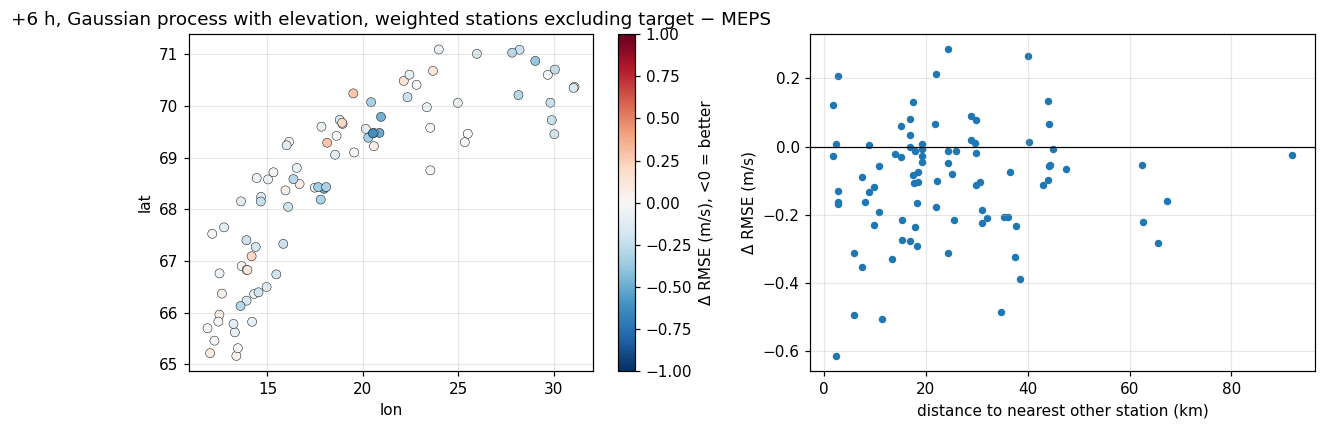

stations improved: 66 / 86


In [10]:
j = list(leads).index(6)
m = TEST[:, j]
def st_rmse(p):
    e2 = ((y[:, j] - p[:, j]) ** 2).sum(-1); e2[~m] = np.nan
    return np.sqrt(np.nanmean(e2, 0))
dr = st_rmse(P['Gaussian process with elevation, weighted stations excluding target']) - st_rmse(P['MEPS uncorrected'])
nn = np.sort(np.linalg.norm(xy[:, None] - xy[None], axis=-1), 1)[:, 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sc = ax[0].scatter(d['lon'], d['lat'], c=dr, cmap='RdBu_r', vmin=-1, vmax=1, s=35, edgecolor='k', lw=.3)
plt.colorbar(sc, ax=ax[0], label='Δ RMSE (m/s), <0 = better'); ax[0].set(xlabel='lon', ylabel='lat', title='+6 h, Gaussian process with elevation, weighted stations excluding target − MEPS')
ax[1].scatter(nn, dr, s=15); ax[1].axhline(0, c='k', lw=.8)
ax[1].set(xlabel='distance to nearest other station (km)', ylabel='Δ RMSE (m/s)')
plt.tight_layout(); plt.show()
print('stations improved:', (dr < 0).sum(), '/', np.isfinite(dr).sum())

**Result 7.** At +6 h, the Gaussian process with elevation, weighted stations excluding
target, lowers the RMSE at 66 of 86 stations. The gains are small: the median change is
−0.09 m/s, and 88 % of stations change by less than ±0.3 m/s. The change is not tied to
the distance to the nearest other station (correlation 0.08).


In [11]:
# save the result tables (used for the text in this notebook)
import os
out = '/cluster/work/projects/nn8106k/siyan/windcast/results/a0'; os.makedirs(out, exist_ok=True)
R.to_csv(f'{out}/rmse.csv'); imp.to_csv(f'{out}/rmse_reduction_pct.csv')
table(TEST, 'mve').to_csv(f'{out}/mean_vector_error.csv')
Rh.to_csv(f'{out}/rmse_highwind.csv'); imph.to_csv(f'{out}/rmse_reduction_highwind_pct.csv')
U.to_csv(f'{out}/crps_coverage.csv')
pd.Series(dr, index=d['station']).to_csv(f'{out}/station_rmse_change_6h.csv')
print(out)

/cluster/work/projects/nn8106k/siyan/windcast/results/a0


## 8. Findings (small experiment, 2018-01 – 07)

Numbers are vector RMSE changes vs MEPS on the test set (summer 2018, 87 stations). +0 h
is not operational, since run t is only out at about t + 3 h, so short-lead numbers should
be read from +3 h on.

1. **The target station's own obs-forecast carries most of the signal, and it decays with
   lead.** Its correlation with the future residual is 0.65 at +3 h, 0.43 at +12 h and
   0.18 at +66 h. Target-station persistence gives −23 % at +3 h, −15 % at +6 h, −7 % at
   +12 h and −5 % at +24 h. Peduto et al. find the same shape over the Atlantic (−45 % at
   +1 h, −13 % at +48 h); here the gain falls off faster.
2. **Other stations add very little.** The correlation with other stations' obs-forecast
   is ≤ 0.13, already within 25 km. With the target station excluded (also from training),
   the Gaussian processes give −3 to −4 % up to +6 h, −1.5 to −2 % at +12 h and ≈ 0 beyond
   +36 h. This matches mtno (optimal interpolation ≤ 0.02–0.04 m/s): in this terrain MEPS
   errors are mostly station-local, not spatially coherent. The fitted kernel says the
   same: nugget 5.6 against spatial variance 3.3.
3. **Elevation in the kernel: no clear gain once the target is strictly excluded.** It
   fits better on all stations (NLL 1.543 vs 1.552), but in held-out RMSE the two kernels
   are equal (−3.1 vs −3.3 % at +6 h). Its parameters vary strongly between held-out
   groups (elevation scale 160–375 m). Only at high winds is it slightly safer than
   distance-only. An earlier run, where the kernel was fitted on all stations, showed a
   small advantage that came from training on the target stations. RQ2 needs better
   terrain descriptors than elevation difference alone.
4. **Ridge regression, weighted stations including target, is the best model from +3 h
   on** (−18 % at +6 h, −11 % at +12 h, −7 % at +48 h). Much of its long-lead gain is a
   static bias correction: ridge regression excluding the target still gets −3 to −6 % at
   every lead.
5. **High winds (≥ 10 m/s): ridge regression degrades at long leads, the Gaussian process
   does not.** Ridge regression is 10–11 % worse than MEPS at +66 h; Peduto et al. report
   the same failure. The Gaussian processes shrink back to MEPS. Target-station
   persistence and the Gaussian process including the target still gain 4 % / 3 % at
   +48 h.
6. **The Gaussian process uncertainty is usable but too wide.** 90 % intervals cover
   93–94 %, and CRPS beats the residual climatology mainly when the target is included,
   at short leads.
7. **The Gaussian process including the target is worse than target-station persistence.**
   It treats the station-local part of the obs-forecast as noise and smooths it away,
   although that part persists in time. The kernel needs a persistent station-local
   component: a nugget that is signal and decays with lag, fitted on (space, lag) jointly.

**Caveats.** Only 7 months. Train is winter / spring and test is summer, so there is a
seasonal shift. Only the obs-forecast at init time is used.

**Next.**

* Rerun when MEPS 2018–2021 is downloaded, with the full splits.
* A space–lag Gaussian process with a persistent station-local component; obs-forecast
  windows of 0–3 h and 0–12 h as an ablation.
* A Gaussian process on the ridge-regression residuals.
* Terrain descriptors in the kernel (fjord / ridge / exposure) instead of elevation only.
* Then the operator side (`neuralop` `GINO` / `FNOGNO` + Gaussian process) on the GPU
  nodes.
